In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_1500.csv', index_col='index')
sequences['fold'] = sequences['fold'].astype(str)

In [3]:
sequences

,cdr1_alpha,cdr2_alpha,cdr3_alpha,cdr1_beta,cdr2_beta,cdr3_beta,peptide,mhc_pseudo,v_alpha,j_alpha,v_beta,j_beta,mhc1,mhc2,mhc_type,species,source,label,fold
index,,,,,,,,,,,,,,,,,,,
66254,DSAIYN,IQSSQRE,AVKLEGSQGNLI,SEHNR,FQNEAQ,ASSLEGQLYEQY,KSKRTPMGF,GERNKASQTRERKARVEQLAYEGLEW,TRAV21*01,TRAJ42*01,TRBV7-9*03,TRBJ2-7*01,HLA-B*57:01,B2M,MH1,Human,shuffling,0,1
77565,DSASVY,IRSNMER,AANTEGADRLT,SGHDT,FRDEAV,ASSFYWGGSYEQY,KAFSPEVIPMF,GERNKASQTRERKARVEQLAYEGLEW,TRAV5-1*01,TRAJ45*01,TRBV14*01,TRBJ2-7*01,HLA-B*57:01,B2M,MH1,Mouse/Human,shuffling,0,1
80823,ATSIAYPN,VITAGQK,ALGSGGSWQLI,LGHNA,YSYQKL,ASSGPEVF,RAQAPPPSW,GERNKASQTRERKARVEQLAYEGLEW,TRAV6D-6,TRAJ2,TRBV2,TRBJ1-1,HLA-B*57:01,B2M,MH1,Mouse/Human,shuffling,0,1
66027,DSASNY,IRSNVGE,ADDYKLS,LNHDA,SQIVND,ASKKTPVGTEAF,KSKRTPMGF,GERNKASQTRERKARVEQLAYEGLEW,TRAV13-1*01,TRAJ20*01,TRBV19*01,TRBJ1-1*01,HLA-B*57:01,B2M,MH1,Human,shuffling,0,1
66033,SIFNT,LYKAGEL,AGSPPPSSGAGPFQLT,MDHEN,SYDVKM,ASSLHRTLLSGNTIY,KSKRTPMGF,GERNKASQTRERKARVEQLAYEGLEW,TRAV35*01,TRAJ28*01,TRBV28*01,TRBJ1-3*01,HLA-B*57:01,B2M,MH1,Human,shuffling,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7477,SSYSPS,YTSAATLV,VVSSNTNAGKST,MGHRA,YSYEKL,ASSQLVGEAYNEQF,MEVTPSGTWL,REQIKTNQTRERKARVEQLAYEGEEW,TRAV8-2*01,TRAJ27*01,TRBV4-1*01,TRBJ2-1*01,HLA-B*40:01,B2M,MH1,Human,VDJdb,1,5
12787,VSGNPY,YITGDNLV,AVTFGNVLHCFGNVLH,MDHEN,SYDVKM,ASKGDRVTDTQY,RVRAYTYSK,QERNKAQQTRVGKAHEEQLAYDGTEW,TRAV3,TRAJ35,TRBV28,TRBJ2-3,HLA-A*03:01,B2M,MH1,Human,ITRAP,1,5
10273,TSGFNG,NVLDGL,AVTLRDYGQNFV,MGHRA,YSYEKL,ASRKTEVSNSYGYT,RVRAYTYSK,QERNKAQQTRVGKAHEEQLAYDGTEW,TRAV1-2,TRAJ26,TRBV4-1,TRBJ1-2,HLA-A*03:01,B2M,MH1,Human,ITRAP,1,5


In [4]:
confidences = pd.read_csv('../data/processed/confidence_scores_af3_tcrmodel2_1500.csv')

In [5]:
confidences['top_model'] = False
confidences.loc[confidences.groupby('structure_name')['ranking_score'].idxmax(), 'top_model'] = True

In [6]:
structural_features = pd.read_csv('../data/processed/predicted_af3_tcrmodel2_structural_features_1500.csv')
structural_features

,pitch_angle,scanning_angle,z_score,name,seed,sample
0,4.690768,36.561768,28.555620,66254,1,0
1,3.224947,38.141120,28.563307,66254,1,1
2,5.748798,34.529160,28.516499,66254,1,2
3,5.018134,32.817474,28.514931,66254,1,3
4,9.198234,46.252075,29.091034,66254,1,4
...,...,...,...,...,...,...
7495,10.725905,138.738390,28.033434,12979,1,0
7496,16.512377,138.501722,29.179110,12979,1,1
7497,14.116955,141.859013,28.576191,12979,1,2
7498,13.524849,142.840013,28.266901,12979,1,3


In [7]:
structural_features = structural_features.dropna()

In [8]:
data_features = (
    confidences.merge(
        structural_features,
        how='inner',
        left_on=['structure_name', 'sample', 'seed'],
        right_on=['name', 'sample', 'seed'],
    )
    .drop('name', axis='columns')
    .merge(sequences[['fold', 'label']], how='left', right_index=True, left_on='structure_name')
    .set_index(['structure_name', 'seed', 'sample'])
)

X = data_features[[col for col in data_features if col not in ('fold', 'label', 'top_model')]]

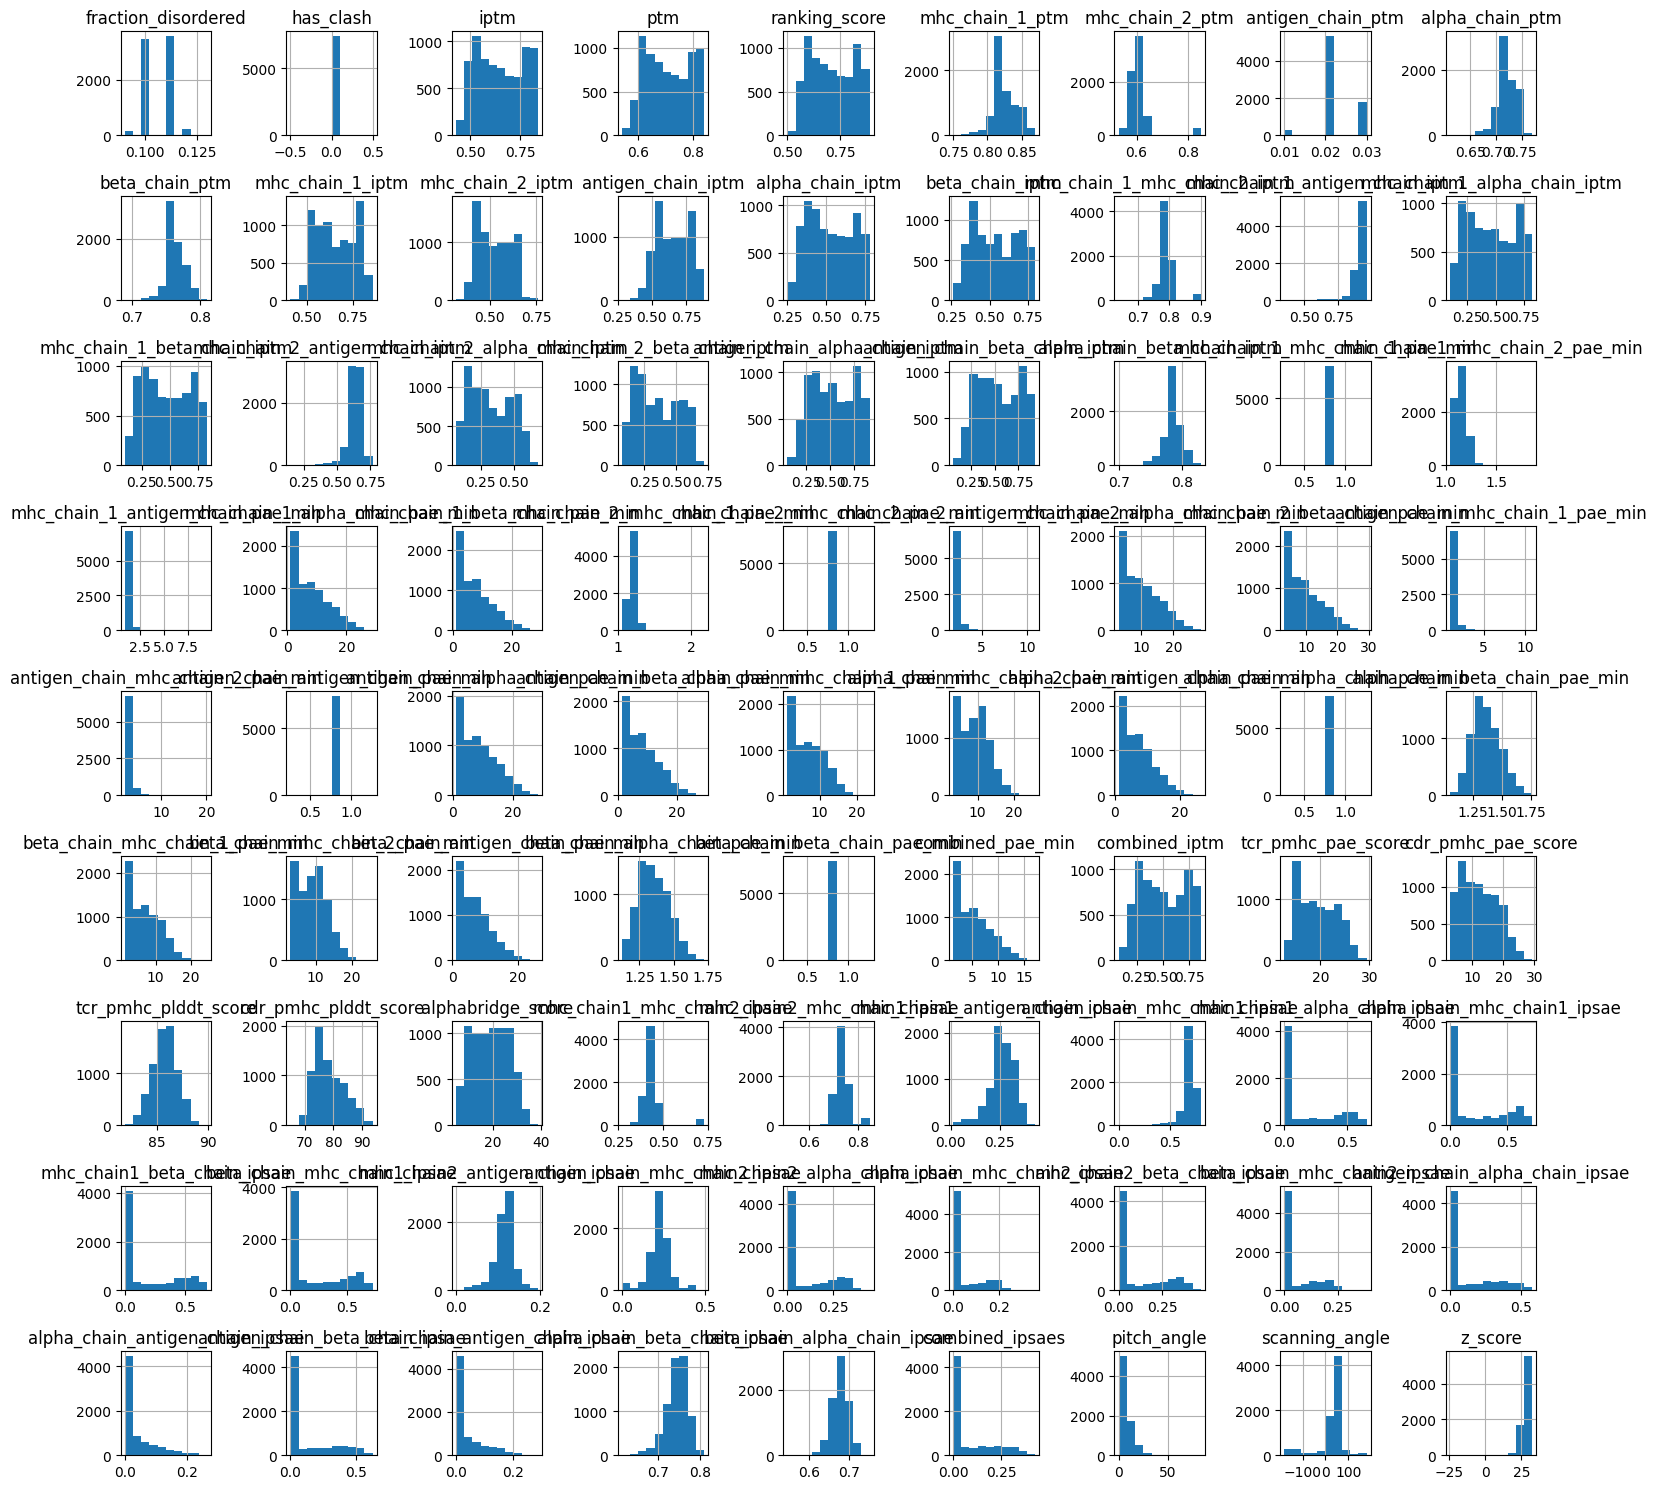

In [9]:
X.hist(figsize=(15, 15))
plt.tight_layout()
plt.show()

In [10]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

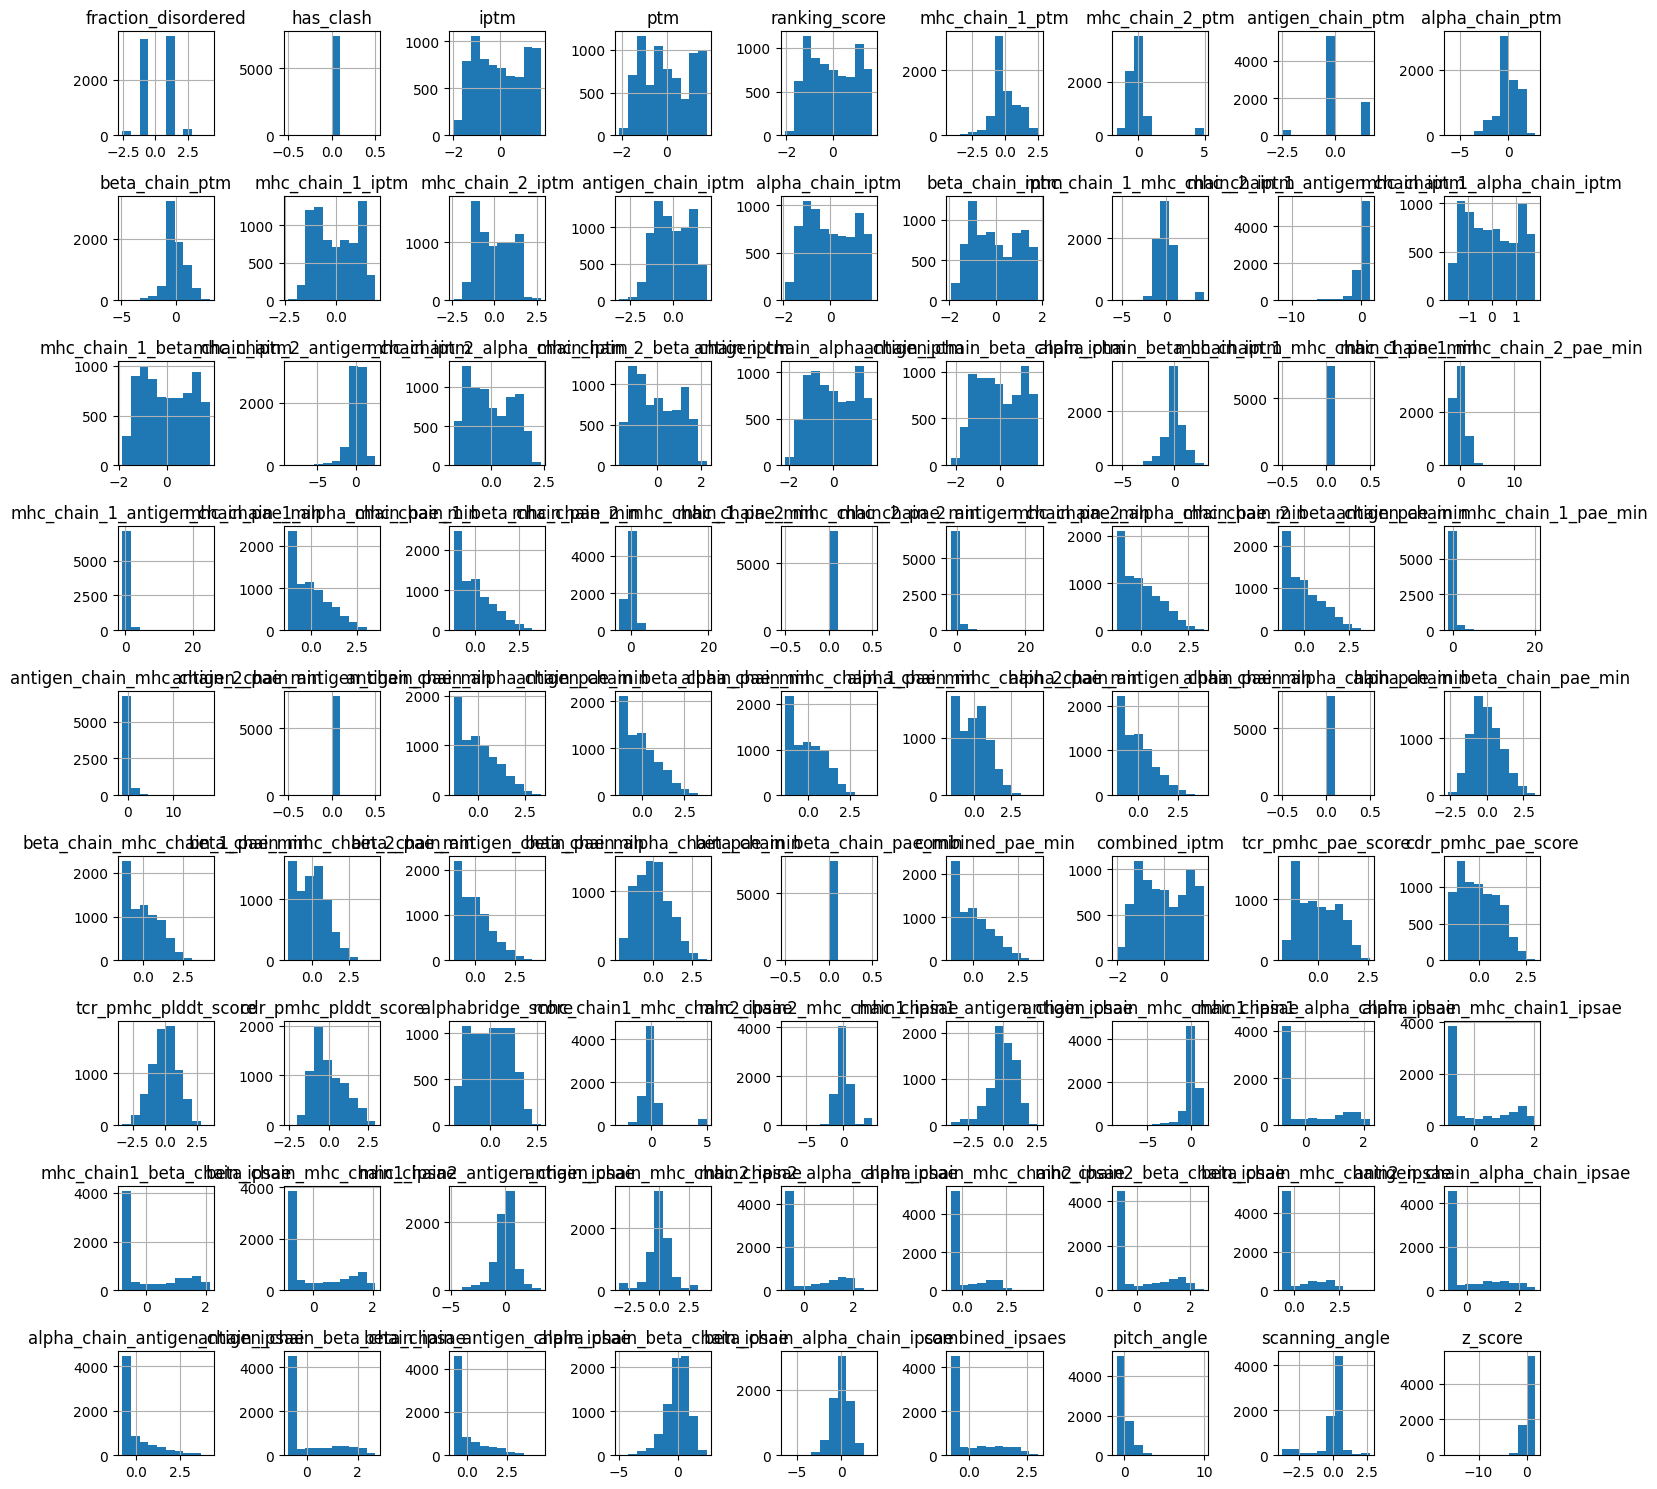

In [11]:
X_scaled.hist(figsize=(15, 15))

plt.tight_layout()
plt.show()

In [12]:
X_pca = PCA(n_components=10).fit_transform(X_scaled)

In [13]:
correlations = {
    'feature': [],
    'pc': [],
    'correlation': [],
    'p_val': [],
}
for col_name in X_scaled.columns:
    for i in range(10):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('error', stats.ConstantInputWarning)
                corr_coef, p_val = stats.pearsonr(X_scaled[col_name], X_pca[:, i])

        except stats.ConstantInputWarning:
            corr_coef = None
            p_val = None

        correlations['feature'].append(col_name)
        correlations['pc'].append(i + 1)
        correlations['correlation'].append(corr_coef**2 if corr_coef else corr_coef)
        correlations['p_val'].append(p_val)

correlations = pd.DataFrame(correlations)

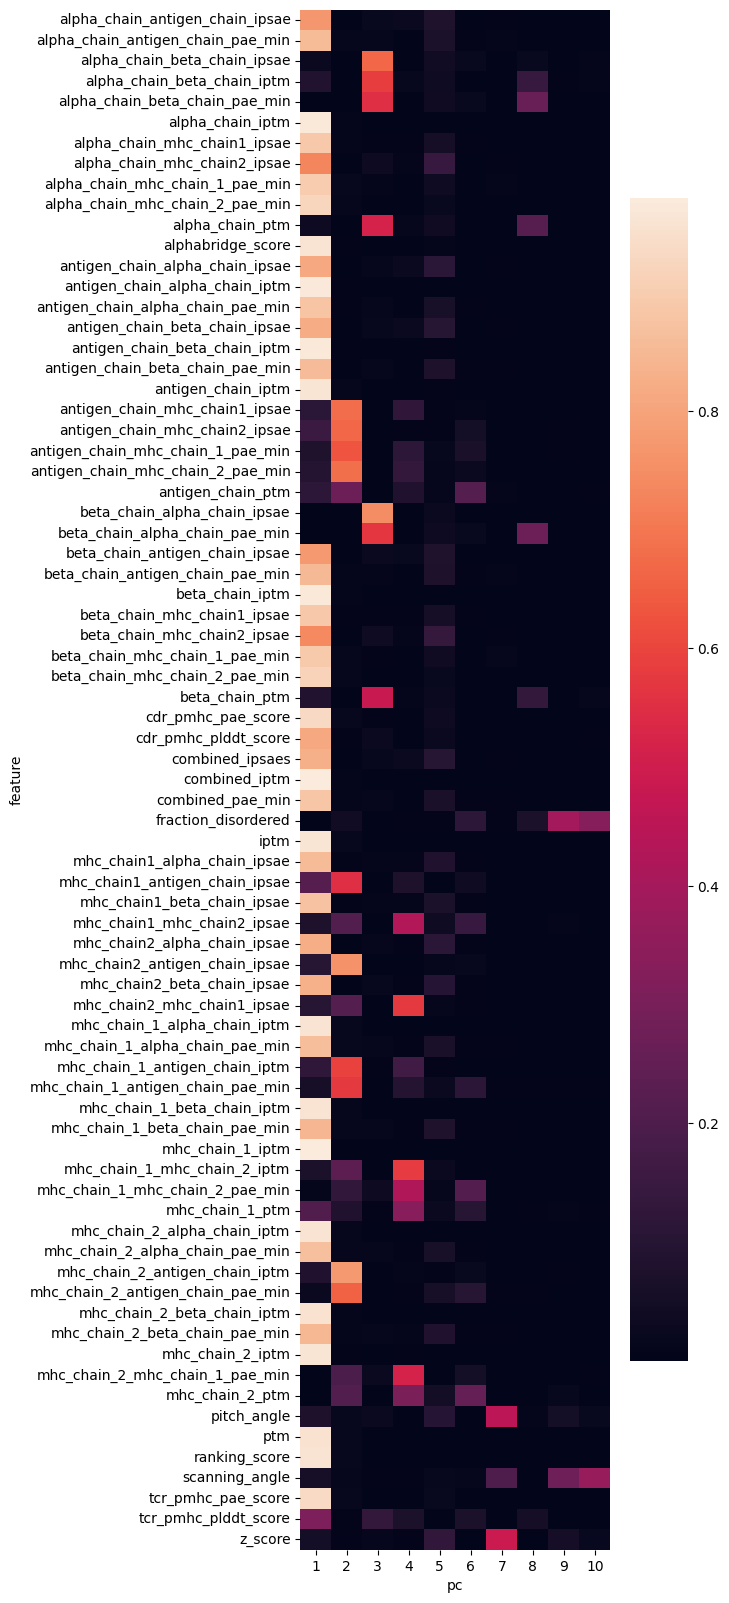

In [14]:
plt.figure(figsize=(5, 20))

sns.heatmap(correlations.pivot_table(index='feature', columns='pc', values='correlation').sort_index())

plt.show()

In [15]:
rf_predictions = []
models = []
for fold in data_features['fold'].unique():
    print('Working on CV fold', fold)
    hold_out_mask = (data_features['fold'] == fold).to_numpy()

    X_train = X_pca[~hold_out_mask]
    X_test = X_pca[hold_out_mask]

    y_train = data_features['label'].to_numpy()[~hold_out_mask]
    y_test = data_features['label'].to_numpy()[hold_out_mask]

    indices_test = data_features[hold_out_mask].index

    model = RandomForestClassifier(random_state=123)
    model.fit(X_train, y_train)
    models.append(model)

    rf_predictions.append(pd.DataFrame(model.predict(X_test), index=indices_test, columns=['prediction']))

rf_predictions = pd.concat(rf_predictions)

Working on CV fold 1


Working on CV fold 2
Working on CV fold 3
Working on CV fold 4
Working on CV fold 5


In [16]:
rf_predictions = rf_predictions.merge(data_features, how='inner', right_index=True, left_index=True)

In [17]:
roc_auc_score(rf_predictions['label'], rf_predictions['prediction'])

0.5636294776496011

In [18]:
1 - roc_auc_score(rf_predictions['label'], rf_predictions['cdr_pmhc_pae_score'])

0.6030700166057656

In [19]:
roc_auc_by_fold = {
    'fold': [],
    'roc_auc_score': [],
    'af3_roc_auc_score': [],
}
for fold, group in rf_predictions.groupby('fold'):
    roc_auc_by_fold['fold'].append(fold)
    roc_auc_by_fold['roc_auc_score'].append(roc_auc_score(group['label'], group['prediction']))
    roc_auc_by_fold['af3_roc_auc_score'].append(1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score']))

roc_auc_by_fold = pd.DataFrame(roc_auc_by_fold)
roc_auc_by_fold = roc_auc_by_fold.melt(id_vars='fold', var_name='model', value_name='score')
roc_auc_by_fold['model'] = roc_auc_by_fold['model'].map(
    {
        'roc_auc_score': 'RF_score',
        'af3_roc_auc_score': 'AF3_score',
    }
)

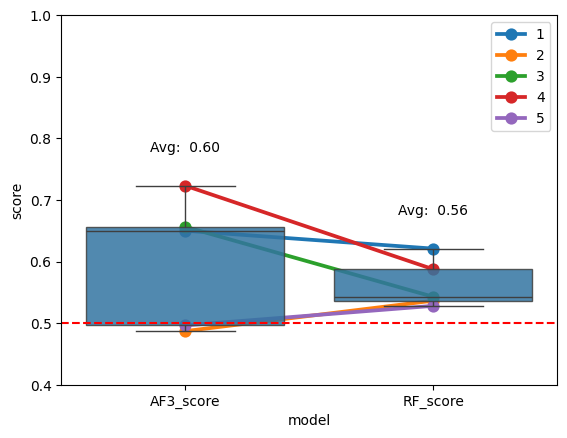

In [20]:
sns.pointplot(roc_auc_by_fold.sort_values('model'), x='model', y='score', hue='fold')
ax = sns.boxplot(roc_auc_by_fold.sort_values('model'), y='score', x='model', boxprops={'alpha': 0.85}, color='C0')

plt.axhline(0.5, color='r', linestyle='dashed')

for i, (_, scores) in enumerate(roc_auc_by_fold.groupby('model')['score']):
    plt.text(i, scores.max() + 0.05, f'Avg: {scores.mean(): .2f}', ha='center', va='bottom', fontsize=10)

plt.ylim(0.4, 1.0)

plt.show()

In [21]:
scores = roc_auc_by_fold.pivot_table(index='fold', columns='model', values='score').to_numpy()
stats.wilcoxon(scores[:, 0], scores[:, 1])

WilcoxonResult(statistic=5.0, pvalue=0.625)